In [6]:
import pandas as pd

In [7]:
df = pd.read_csv('/content/customer_behavior.csv')



In [8]:
# Calculate Average (Mean)
average = df['PurchaseAmount'].mean()
print(average)

1003.9506701030928


In [9]:
# Calculate Median
median = df['PurchaseAmount'].median()
print(median)

998.0799999999999


In [10]:
# Calculate Mode
mode = df['PurchaseAmount'].mode()
print(mode)

0    0.0
Name: PurchaseAmount, dtype: float64


##Are there any outliers in the PurchaseAmount data?

In [11]:
# Find the first quartile (Q1)
Q1 = df['PurchaseAmount'].quantile(0.25)
print("Q1:", Q1)

# Find the third quartile (Q3)
Q3 = df['PurchaseAmount'].quantile(0.75)
print("Q3:", Q3)

# Calculate Interquartile Range (IQR)
IQR = Q3 - Q1
print("IQR:", IQR)

# Calculate lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)


# Identify outliers
outliers = df[(df['PurchaseAmount'] < lower_limit) |
              (df['PurchaseAmount'] > upper_limit)]


print("Number of Outliers:", len(outliers))
print("Outlier Values:")
print(outliers['PurchaseAmount'])




Q1: 673.6424999999999
Q3: 1327.0775
IQR: 653.4350000000002
Lower Limit: -306.51000000000033
Upper Limit: 2307.2300000000005
Number of Outliers: 15
Outlier Values:
195     2318.33
265     2496.41
348     2688.69
411     2349.16
826     2578.89
1358    2384.19
2285    2457.05
2557    2316.19
2681    2400.69
3326    2357.41
3438    2688.88
3564    2643.88
4345    2472.62
4693    2484.75
4808    2642.06
Name: PurchaseAmount, dtype: float64


##Is there any skewness or kurtosis in the PurchaseAmount distribution?

In [12]:
purchase_amounts = df['PurchaseAmount'].dropna()

In [13]:
from scipy import stats

In [14]:
print("Skewness:", df['PurchaseAmount'].skew())
print("Kurtosis:", df['PurchaseAmount'].kurtosis())

Skewness: 0.10609189374631554
Kurtosis: -0.2615105545319705


##Is there a significant difference in spending between male and female customers?

In [15]:
df_clean = df.dropna(subset=['PurchaseAmount', 'Gender'])

In [16]:
#Separate purchase amounts for Male and Female customers
male_spending = df_clean[df_clean['Gender'] == 'Male']['PurchaseAmount']
female_spending = df_clean[df_clean['Gender'] == 'Female']['PurchaseAmount']

In [17]:
# Run an Independent t-test (Welch's t-test does not assume equal variances)
t_stat, p_value = stats.ttest_ind(male_spending, female_spending, equal_var=False)

# Print results
print(f"Mean Male Spending: {male_spending.mean():.2f}")
print(f"Mean Female Spending: {female_spending.mean():.2f}")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

#Conclusion at a 5% significance level (alpha = 0.05)
if p_value < 0.05:
    print("Conclusion: There IS a statistically significant difference in spending between genders.")
else:
    print("Conclusion: There is NO statistically significant difference in spending between genders.")

Mean Male Spending: 1019.18
Mean Female Spending: 987.87
T-statistic: 2.2348
P-value: 0.0255
Conclusion: There IS a statistically significant difference in spending between genders.


#Is there a relationship between ProductCategory and customer churn?

In [19]:
# Create a contingency table (cross-tabulation of Product Category vs. Churn)

contingency_table = pd.crosstab(df['ProductCategory'], df['Churn'])

print("--- Customer Counts by Product Category and Churn ---")
print(contingency_table)

--- Customer Counts by Product Category and Churn ---
Churn             No  Yes
ProductCategory          
Electronics      785  541
Fashion          839  607
Grocery          855  604


In [22]:
# 3. Perform the Chi-Square Test of Independence
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)

# 4. Print the statistical results
print(f"\nChi-Square Statistic: {chi2:.4f}")
print(f"Degrees of Freedom (dof): {dof}")
print(f"P-value: {p_value:.4f}")

# 5. Conclusion at a 5% significance level (alpha = 0.05)
if p_value < 0.05:
    print("\nConclusion: There IS a statistically significant relationship between Product Category and Churn.")
else:
    print("\nConclusion: There is NO statistically significant relationship between Product Category and Churn.")


Chi-Square Statistic: 0.3960
Degrees of Freedom (dof): 2
P-value: 0.8204

Conclusion: There is NO statistically significant relationship between Product Category and Churn.


##Does PurchaseAmount vary significantly across different regions?

In [23]:
# 2. View the average spending for each region to compare them easily
region_stats = df.groupby('Region')['PurchaseAmount'].mean()
print("--- Average Spending by Region ---")
print(round(region_stats, 2))

# 3. Separate purchase amounts for each region into their own lists
east = df[df['Region'] == 'East']['PurchaseAmount'].dropna()
north = df[df['Region'] == 'North']['PurchaseAmount'].dropna()
south = df[df['Region'] == 'South']['PurchaseAmount'].dropna()
west = df[df['Region'] == 'West']['PurchaseAmount'].dropna()

# 4. Perform a One-Way ANOVA test to compare means across all regions
f_statistic, p_value = stats.f_oneway(east, north, south, west)

print(f"\nANOVA F-statistic: {f_statistic:.4f}")
print(f"P-value: {p_value:.4f}")

# 5. Conclusion at a 5% significance level (alpha = 0.05)
if p_value < 0.05:
    print("\nConclusion: Purchase amounts DO vary significantly across different regions.")
else:
    print("\nConclusion: There is NO significant difference in purchase amounts across regions.")

--- Average Spending by Region ---
Region
East     1009.95
North    1013.02
South     997.60
West      995.25
Name: PurchaseAmount, dtype: float64

ANOVA F-statistic: 0.3897
P-value: 0.7605

Conclusion: There is NO significant difference in purchase amounts across regions.


##Which email campaign (A or B) performed better in terms of average PurchaseAmount?

In [24]:
# 2. Group the data by CampaignGroup and calculate the average (mean) purchase amount
average_spending = df.groupby('CampaignGroup')['PurchaseAmount'].mean()

print("--- Average Purchase Amount by Campaign Group ---")
print(round(average_spending, 2))

# 3. Simple comparison to find which one performed better
mean_a = average_spending['A']
mean_b = average_spending['B']

if mean_a > mean_b:
    print(f"\nConclusion: Campaign A performed better with a higher average purchase amount of {mean_a:.2f}.")
else:
    print(f"\nConclusion: Campaign B performed better with a higher average purchase amount of {mean_b:.2f}.")

--- Average Purchase Amount by Campaign Group ---
CampaignGroup
A    1011.95
B     994.34
Name: PurchaseAmount, dtype: float64

Conclusion: Campaign A performed better with a higher average purchase amount of 1011.95.


#Can we assume PurchaseAmount follows a normal distribution?

In [25]:
import matplotlib.pyplot as plt

In [26]:
# 2. Drop missing values in PurchaseAmount
purchases = df['PurchaseAmount'].dropna()

In [27]:
# 3. Print Skewness and Kurtosis (Quick Numerical Check)
# A normal distribution has a skewness of 0 and excess kurtosis of 0.
print(f"Skewness: {purchases.skew():.4f}")
print(f"Kurtosis: {purchases.kurtosis():.4f}")

Skewness: 0.1061
Kurtosis: -0.2615


In [28]:
# 4. Statistical Test (Shapiro-Wilk test for normality)
# H0: The data is normally distributed
# If p-value < 0.05, we reject the null hypothesis (meaning it is NOT normal)
stat, p_value = stats.shapiro(purchases.sample(min(len(purchases), 5000), random_state=42))
print(f"Shapiro-Wilk P-value: {p_value}")

if p_value < 0.05:
    print("Conclusion: The data does NOT follow a normal distribution.")
else:
    print("Conclusion: The data follows a normal distribution.")

Shapiro-Wilk P-value: 5.74412779948217e-12
Conclusion: The data does NOT follow a normal distribution.


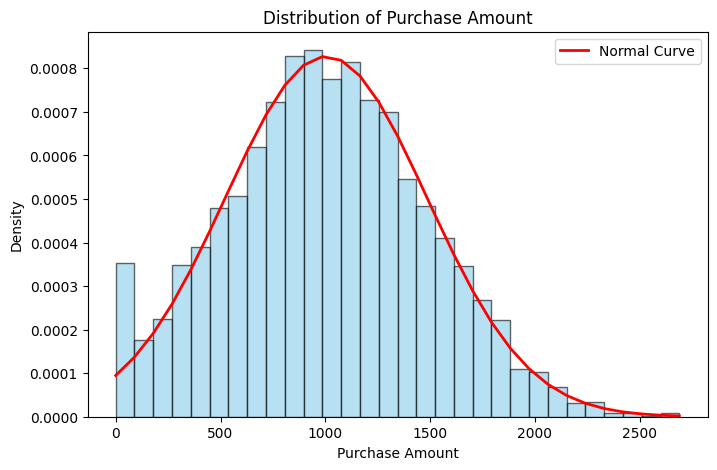

In [29]:
# 5. Visual Check: Create a Histogram with a Normal Curve
plt.figure(figsize=(8, 5))
count, bins, ignored = plt.hist(purchases, bins=30, density=True, alpha=0.6, color='skyblue', edgecolor='black')

# Plot the fitted normal curve
mu, std = purchases.mean(), purchases.std()
plt.plot(bins, stats.norm.pdf(bins, mu, std), color='red', linewidth=2, label='Normal Curve')

plt.title('Distribution of Purchase Amount')
plt.xlabel('Purchase Amount')
plt.ylabel('Density')
plt.legend()
plt.show()

#9. What insights can we gain by applying the Central Limit Theorem?

In [30]:
import numpy as np

Original Population Mean: 1003.95
Average of the Sample Means: 1001.64


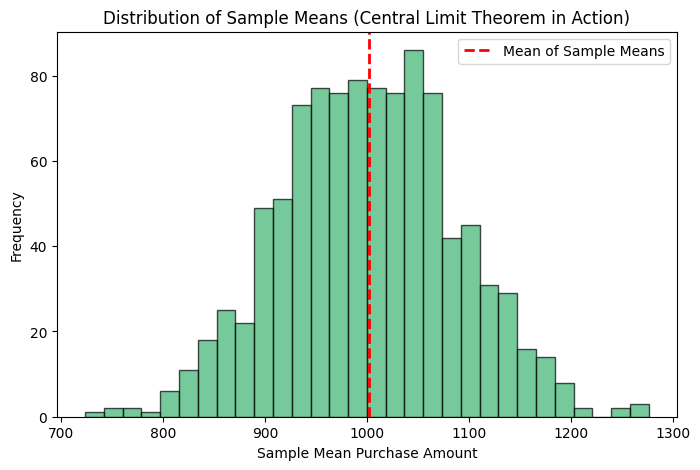

In [31]:
purchases = df['PurchaseAmount'].dropna()

# 2. Simulate the Central Limit Theorem
sample_size = 30       # Number of customers in each sample
num_samples = 1000     # How many times we take a sample

sample_means = []

for i in range(num_samples):
    # Take a random sample of size 30
    sample = purchases.sample(n=sample_size, replace=True)
    # Calculate the mean of this sample and store it
    sample_means.append(sample.mean())

# 3. Print out insights
print(f"Original Population Mean: {purchases.mean():.2f}")
print(f"Average of the Sample Means: {np.mean(sample_means):.2f}")

# 4. Visualizing the CLT
plt.figure(figsize=(8, 5))
plt.hist(sample_means, bins=30, color='mediumseagreen', edgecolor='black', alpha=0.7)
plt.axvline(np.mean(sample_means), color='red', linestyle='--', linewidth=2, label='Mean of Sample Means')

plt.title('Distribution of Sample Means (Central Limit Theorem in Action)')
plt.xlabel('Sample Mean Purchase Amount')
plt.ylabel('Frequency')
plt.legend()
plt.show()

#10.What is the 95% confidence interval for the average PurchaseAmount?

In [32]:
# 2. Drop any missing values in PurchaseAmount
purchases = df['PurchaseAmount'].dropna()

# 3. Calculate sample mean and standard error of the mean (SEM)
sample_mean = purchases.mean()
sem = stats.sem(purchases)  # Standard error measures variability between sample means

# 4. Calculate the 95% Confidence Interval
# df=len(purchases)-1 represents the degrees of freedom
confidence_interval = stats.t.interval(confidence=0.95, df=len(purchases)-1, loc=sample_mean, scale=sem)

# 5. Display the results
print(f"Sample Mean Purchase Amount: {sample_mean:.2f}")
print(f"95% Confidence Interval: ({confidence_interval[0]:.2f}, {confidence_interval[1]:.2f})")

Sample Mean Purchase Amount: 1003.95
95% Confidence Interval: (990.38, 1017.52)
